# End-to-End Data Analytics Pipeline

This project focuses on data cleaning, anonymization, analysis, and visualization of transaction data.

In [2]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df=pd.read_csv("ecommerce_transactions.csv")
df.head()

,Transaction_ID,User_Name,Age,Country,Product_Category,Purchase_Amount,Payment_Method,Transaction_Date
0,1,Ava Hall,63,Mexico,Clothing,780.69,Debit Card,14-04-23
1,2,Sophia Hall,59,India,Beauty,738.56,PayPal,30-07-23
2,3,Elijah Thompson,26,France,Books,178.34,Credit Card,17-09-23
3,4,Elijah White,43,Mexico,Sports,401.09,UPI,21-06-23
4,5,Ava Harris,48,Germany,Beauty,594.83,Net Banking,29-10-24


## Data Understanding

The dataset contains transaction-level information including user details, product categories, and payment methods.

In [7]:
#get all info you need about the data
df.info()
df.describe()
df.isnull().sum()
print(df.columns)
df.columns = df.columns.str.strip()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    50000 non-null  int64  
 1   User_Name         50000 non-null  object 
 2   Age               50000 non-null  int64  
 3   Country           50000 non-null  object 
 4   Product_Category  50000 non-null  object 
 5   Purchase_Amount   50000 non-null  float64
 6   Payment_Method    50000 non-null  object 
 7   Transaction_Date  50000 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 3.1+ MB
Index(['Transaction_ID', 'User_Name', 'Age', 'Country', 'Product_Category',
       'Purchase_Amount', 'Payment_Method', 'Transaction_Date'],
      dtype='object')


## Data Cleaning

Handling missing values, removing duplicates, and preparing the dataset for analysis.

In [10]:
#Data Cleaning
df.drop_duplicates(inplace=True)
df.isnull().sum()

Transaction_ID      0
User_Name           0
Age                 0
Country             0
Product_Category    0
Purchase_Amount     0
Payment_Method      0
Transaction_Date    0
dtype: int64

In [12]:
#Data Analysis
# Total sales by product
df.groupby("Product_Category")["Purchase_Amount"].sum()

# Payment method distribution
df["Payment_Method"].value_counts()

Payment_Method
UPI                 8477
Cash on Delivery    8434
Debit Card          8355
Credit Card         8310
PayPal              8250
Net Banking         8174
Name: count, dtype: int64

In [14]:
df["Transaction_Date"].head()

0    14-04-23
1    30-07-23
2    17-09-23
3    21-06-23
4    29-10-24
Name: Transaction_Date, dtype: object

## Data Anonymization

Sensitive user information such as names and exact age is transformed or removed to ensure privacy while maintaining analytical value.

In [17]:
# Data Anonymization

# Age → Age Group
df["Age_Group"] = pd.cut(df["Age"],
                        bins=[0,25,35,50,100],
                        labels=["18-25","26-35","36-50","50+"])

# Convert date safely
df["Transaction_Date"] = pd.to_datetime(df["Transaction_Date"], errors='coerce')

# Remove invalid dates
df.dropna(subset=["Transaction_Date"], inplace=True)

# Extract month
df["Month"] = df["Transaction_Date"].dt.month_name()

# Fix month order
month_order = ["January","February","March","April","May","June",
               "July","August","September","October","November","December"]

df["Month"] = pd.Categorical(df["Month"], categories=month_order, ordered=True)

# Sales over time
monthly_sales = df.groupby("Month")["Purchase_Amount"].sum()

# Drop sensitive columns
df.drop(["User_Name", "Age"], axis=1, inplace=True)

C:\Users\admin\AppData\Local\Temp\ipykernel_2408\669858801.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Transaction_Date"] = pd.to_datetime(df["Transaction_Date"], errors='coerce')
C:\Users\admin\AppData\Local\Temp\ipykernel_2408\669858801.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  monthly_sales = df.groupby("Month")["Purchase_Amount"].sum()


## Data Analysis and Visualization

Analyzing trends and patterns in transaction data to extract meaningful business insights.

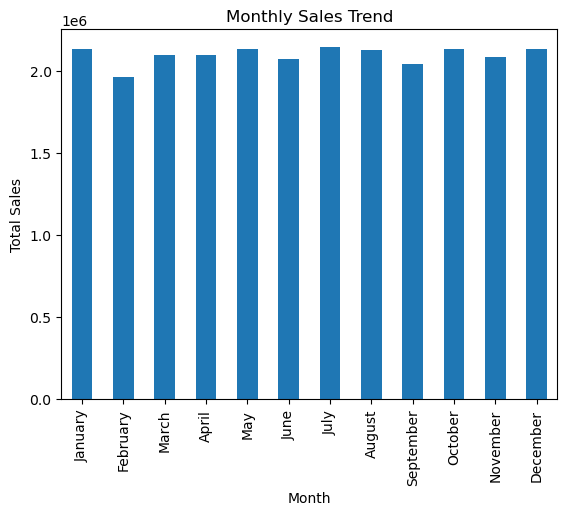

In [19]:
#Data Visualization
monthly_sales.plot(kind="bar")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()

## Key Insights

- Sales remain stable throughout the year  
- February shows the lowest sales  
- Mid-year and festive months show higher performance  
- Business is not heavily seasonal  

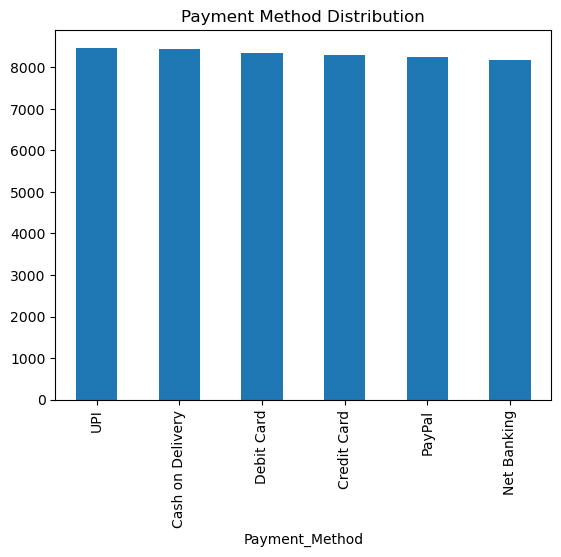

In [23]:
#payment method analysis
df["Payment_Method"].value_counts().plot(kind="bar")
plt.title("Payment Method Distribution")
plt.show()